# Section 1: Setup

This section configures the environment, registers random seeds to ensure strict reproducibility across runs, and checks for CUDA GPU availability to speed up model training and evaluation.

### Requirements:
We check for and import `torch`, `torchvision`, `matplotlib`, `seaborn`, `scikit-learn`, `pandas`, `torchinfo`, and `thop`.

In [1]:
# 1. Environment Package Verification and Installation
import sys
import subprocess

required_packages = ["torch", "torchvision", "matplotlib", "seaborn", "scikit-learn", "pandas", "torchinfo", "thop"]
for pkg in required_packages:
    try:
        __import__(pkg)
    except ImportError:
        print(f"Installing missing package: {pkg}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

# 2. Imports
import os
import random
import time
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
import torchvision.transforms as transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torchinfo import summary
import thop

print("All libraries successfully imported.")

Installing missing package: scikit-learn


All libraries successfully imported.


In [2]:
# 3. Reproducibility Configuration (Setting Seeds)
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Random seed set to: {seed}")

set_seed(42)

Random seed set to: 42


In [3]:
# 4. Device Configuration (CUDA Check)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
else:
    device = torch.device("cpu")
    print("WARNING: CUDA is not available. Falling back to CPU. Training will be extremely slow!")
import torch
print(torch.__version__)

Using GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA Version: 12.4
2.6.0+cu124


In [4]:
# 5. Output Directory Setup
output_dir = "results"
os.makedirs(output_dir, exist_ok=True)
print(f"Results directory ready: {output_dir}")

Results directory ready: results


# Section 2: Data Exploration

This section audits the dataset folders, parses a sample XML file, programmatically checks class names, determines class counts, inspects image shapes, and counts multi-label files.

In [5]:
# 1. Dataset Directory Audit
dataset_dir = "."  # Assuming the notebook is run from the project root directory
train_dir = os.path.join(dataset_dir, "train_PVELAD", "train")
othertypes_dir = os.path.join(dataset_dir, "othertypes_PVELAD", "othertypes")

print("Checking directories:")
print(f"Train path exists: {os.path.exists(train_dir)}")
print(f"Othertypes path exists: {os.path.exists(othertypes_dir)}")

Checking directories:
Train path exists: True
Othertypes path exists: True


In [6]:
# 2. Inspect a Random XML Bounding Box Annotation File
train_xml_dir = os.path.join(train_dir, "Annotations")
if os.path.exists(train_xml_dir):
    xml_files = [f for f in os.listdir(train_xml_dir) if f.endswith('.xml')]
    if xml_files:
        sample_xml = xml_files[0]
        sample_path = os.path.join(train_xml_dir, sample_xml)
        print(f"Displaying content of sample annotation file: {sample_xml}\n")
        with open(sample_path, 'r') as f:
            print(f.read())
    else:
        print("No XML files found in Annotations.")
else:
    print("Annotations folder does not exist.")

Displaying content of sample annotation file: img000001.xml

<?xml version="1.0" ?><annotation>
	<folder>blcak</folder>
	<filename>100_bc.jpg</filename>
	<path>C:\dataset\100_bc.jpg</path>
	<source>
		<database>Unknown</database>
	</source>
	<size>
		<width>1024</width>
		<height>1024</height>
		<depth>1</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>black_core</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>47</xmin>
			<ymin>69</ymin>
			<xmax>961</xmax>
			<ymax>967</ymax>
		</bndbox>
	</object>
</annotation>


In [7]:
# 3. Class Counts & Resolution Checks
# Rarity-based priority (scratch is rarest, finger is most common)
priority_classes = ['scratch', 'fragment', 'corner', 'star_crack', 'thick_line', 'black_core', 'crack', 'finger']
priority_map = {name: idx for idx, name in enumerate(priority_classes)}

# XML parsing logic to scan and check multi-label occurrences
xml_counts = {c: 0 for c in priority_classes}
multi_label_count = 0
total_xmls = 0
image_sizes = set()

if os.path.exists(train_xml_dir):
    for f in os.listdir(train_xml_dir):
        if not f.endswith('.xml'):
            continue
        total_xmls += 1
        tree = ET.parse(os.path.join(train_xml_dir, f))
        root = tree.getroot()
        
        # Check image resolution
        size_node = root.find('size')
        if size_node is not None:
            w = int(size_node.find('width').text)
            h = int(size_node.find('height').text)
            d = int(size_node.find('depth').text)
            image_sizes.add((w, h, d))
            
        objs = root.findall('object')
        img_classes = [obj.find('name').text for obj in objs]
        for c in img_classes:
            if c in xml_counts:
                xml_counts[c] += 1
                
        if len(set(img_classes)) > 1:
            multi_label_count += 1

print(f"Total XML Annotation Files: {total_xmls}")
print(f"Multi-label Images (containing multiple unique defect classes): {multi_label_count}")
print(f"Raw Object Class Occurrences in XMLs: {xml_counts}")
print(f"Unique image resolutions and channels found: {image_sizes}")

Total XML Annotation Files: 3706
Multi-label Images (containing multiple unique defect classes): 659
Raw Object Class Occurrences in XMLs: {'scratch': 5, 'fragment': 7, 'corner': 9, 'star_crack': 135, 'thick_line': 981, 'black_core': 1028, 'crack': 1260, 'finger': 2957}
Unique image resolutions and channels found: {(1024, 1024, 1), (512, 512, 1), (1024, 1024, 3)}


In [8]:
# 4. Audit othertypes_PVELAD subfolders
subfolders = ["good", "dislocation", "meterial"]
othertypes_counts = {}
for sub in subfolders:
    sub_path = os.path.join(othertypes_dir, sub)
    if os.path.exists(sub_path):
        files = [f for f in os.listdir(sub_path) if f.lower().endswith(('.jpg', '.jpeg'))]
        othertypes_counts[sub] = len(files)
    else:
        othertypes_counts[sub] = 0

print("Othertypes counts (by subfolder name):")
print(othertypes_counts)

Othertypes counts (by subfolder name):
{'good': 11351, 'dislocation': 901, 'meterial': 3247}


# Section 3: Data Pipeline

This section defines the PyTorch Dataset class, performs a robust stratified train/validation/test split, sets up transformations/augmentations, builds a weighted sampler to tackle class imbalance, and instantiates DataLoaders.

### Multi-Label Image Resolution:
If an XML annotation contains multiple defects, we use a deterministic priority mapping based on rarity:
1. `scratch` (highest priority - rarest)
2. `fragment`
3. `corner`
4. `star_crack`
5. `thick_line`
6. `black_core`
7. `crack`
8. `finger` (lowest priority - most common)

### Class Mapping (11 categories):
* `good` -> 0
* `crack` -> 1
* `finger` -> 2
* `black_core` -> 3
* `thick_line` -> 4
* `star_crack` -> 5
* `corner` -> 6
* `fragment` -> 7
* `scratch` -> 8
* `dislocation` -> 9
* `meterial` -> 10

In [9]:
# 1. Custom Dataset Path and Label Pre-processing
from dataset_helper import load_all_dataset_paths

file_paths, labels, class_to_id = load_all_dataset_paths()
id_to_class = {v: k for k, v in class_to_id.items()}

print(f"Total labeled samples gathered: {len(file_paths)}")
print("Combined Class distribution:")
unique, counts = np.unique(labels, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {id_to_class[u]} (label {u}): {c}")

Total labeled samples gathered: 19205
Combined Class distribution:
  good (label 0): 11351
  crack (label 1): 825
  finger (label 2): 963
  black_core (label 3): 1006
  thick_line (label 4): 773
  star_crack (label 5): 122
  corner (label 6): 7
  fragment (label 7): 7
  scratch (label 8): 3
  dislocation (label 9): 901
  meterial (label 10): 3247


In [10]:
# 2. Robust Stratified Train / Validation / Test Split
from dataset_helper import robust_stratified_split

train_idx, val_idx, test_idx = robust_stratified_split(file_paths, labels, train_ratio=0.70, val_ratio=0.15, test_ratio=0.15)
print(f"Train split size: {len(train_idx)} | Val split size: {len(val_idx)} | Test split size: {len(test_idx)}")

Train split size: 13443 | Val split size: 2881 | Test split size: 2881


In [11]:
# 3. Custom PyTorch Dataset Class
from dataset_helper import SolarPanelDataset

In [12]:
# 4. Image Transformations & Augmentations
# Resize to 224x224 for DenseNet121, augment training, normalize using ImageNet standards
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = SolarPanelDataset(file_paths[train_idx], labels[train_idx], transform=train_transform)
val_dataset = SolarPanelDataset(file_paths[val_idx], labels[val_idx], transform=val_test_transform)
test_dataset = SolarPanelDataset(file_paths[test_idx], labels[test_idx], transform=val_test_transform)

In [13]:
# 5. DataLoaders Setup
# Set batch size to 32, pin memory for faster GPU transfer
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=True, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=True, num_workers=4)

print("DataLoaders instantiated successfully.")

DataLoaders instantiated successfully.


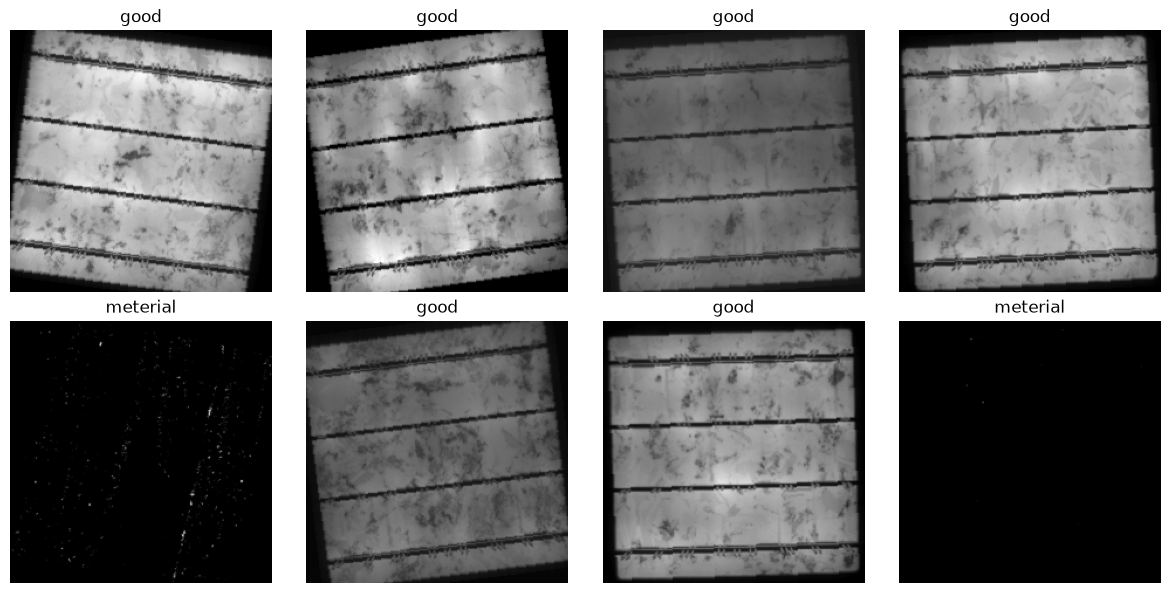

In [14]:
# 6. Visualize Sample Augmented Images
def show_batch(dl):
    for images, labels in dl:
        plt.figure(figsize=(12, 6))
        for i in range(min(8, len(images))):
            plt.subplot(2, 4, i + 1)
            # Unnormalize image for visualization
            img = images[i].numpy().transpose((1, 2, 0))
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            img = std * img + mean
            img = np.clip(img, 0, 1)
            plt.imshow(img)
            plt.title(id_to_class[labels[i].item()])
            plt.axis('off')
        plt.tight_layout()
        plt.show()
        break

show_batch(train_loader)

# Section 4: Phased Model Training

This section defines the training process:
1. Load a pre-trained DenseNet121 model.
2. Replace its classifier head with a custom fully-connected layers structure matching our 11 classes.
3. Handle class imbalance in loss computation using a weighted CrossEntropyLoss.
4. Set up an AdamW optimizer and a ReduceLROnPlateau scheduler.
5. **Phase 1 Training:** Freeze the feature extraction backbone and train the custom classification head for 3 epochs.
6. **Phase 2 Fine-tuning:** Unfreeze block 4 (late layers) of DenseNet121 and fine-tune with a 10x smaller learning rate.
7. Monitor validation F1-macro to run early stopping, and save the best model weights to `results/solarguard_best.pth`.

In [15]:
# 1. Model Definition (DenseNet121 with custom head)
def get_model(num_classes=11):
    # Load pre-trained DenseNet121
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
    
    # Custom classifier head with Dropout
    num_ftrs = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(num_ftrs, num_classes)
    )
    return model

model = get_model(num_classes=11).to(device)
print("Model initialized and moved to device.")

Model initialized and moved to device.


In [16]:
# 2. Loss and Optimizers Setup
# Compute training class frequencies to calculate weighted CrossEntropyLoss
# We use square-root scaling of inverse frequency to stabilize minority class updates
train_labels = labels[train_idx]
inv_freq = []
for c in range(11):
    count = np.sum(train_labels == c)
    inv_freq.append(1.0 / np.sqrt(count) if count > 0 else 1.0)

# Normalize weights relative to 'good' class (label 0)
class_weights_list = [w / inv_freq[0] for w in inv_freq]

class_weights_tensor = torch.tensor(class_weights_list, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
print("Weighted CrossEntropyLoss configured. Weights:", class_weights_list)

Weighted CrossEntropyLoss configured. Weights: [np.float64(1.0), np.float64(3.707749296310453), np.float64(3.4335575584833866), np.float64(3.3596029256716955), np.float64(3.8324425014345898), np.float64(9.668627252158212), np.float64(39.864771415373745), np.float64(39.864771415373745), np.float64(89.1403387922662), np.float64(3.548620856636017), np.float64(1.8697113417690483)]


In [17]:
# 3. Phased Training Loop Implementation
def train_model(model, train_loader, val_loader, criterion, num_epochs_p1=3, num_epochs_p2=10, patience=5):
    # --- PHASE 1: Train Head Only ---
    print("\n=== Phase 1: Training Classification Head Only ===")
    # Freeze all parameters
    for param in model.parameters():
        param.requires_grad = False
    # Unfreeze classifier head parameters
    for param in model.classifier.parameters():
        param.requires_grad = True
        
    optimizer = optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
    
    best_val_f1 = 0.0
    best_model_weights = None
    epochs_no_improve = 0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    
    # Phase 1 training loop
    for epoch in range(num_epochs_p1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
        train_loss = running_loss / total
        train_acc = correct / total
        
        # Validation
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0
        all_preds = []
        all_targets = []
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                
                val_running_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                val_total += targets.size(0)
                val_correct += predicted.eq(targets).sum().item()
                all_preds.extend(predicted.cpu().numpy())
                all_targets.extend(targets.cpu().numpy())
                
        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total
        val_f1 = f1_score(all_targets, all_preds, average='macro')
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        
        print(f"P1 Epoch {epoch+1}/{num_epochs_p1} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1-Macro: {val_f1:.4f}")
        
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model_weights = model.state_dict().copy()
            torch.save(best_model_weights, os.path.join("results", "solarguard_best.pth"))
            
    # --- PHASE 2: Fine-Tuning ---
    print("\n=== Phase 2: Fine-Tuning Block 4 + Classifier ===")
    # Unfreeze denseblock4 parameters
    for name, param in model.named_parameters():
        if "features.denseblock4" in name or "features.norm5" in name or "classifier" in name:
            param.requires_grad = True
        else:
            param.requires_grad = False
            
    # Use 10x smaller learning rate for backbone layers compared to classifier head
    params_group = [
        {"params": [p for n, p in model.named_parameters() if "classifier" in n], "lr": 1e-4},
        {"params": [p for n, p in model.named_parameters() if ("denseblock4" in n or "norm5" in n)], "lr": 1e-5}
    ]
    optimizer = optim.AdamW(params_group, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2, verbose=True)
    
    # Phase 2 training loop
    for epoch in range(num_epochs_p2):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
        train_loss = running_loss / total
        train_acc = correct / total
        
        # Validation
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0
        all_preds = []
        all_targets = []
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                
                val_running_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                val_total += targets.size(0)
                val_correct += predicted.eq(targets).sum().item()
                all_preds.extend(predicted.cpu().numpy())
                all_targets.extend(targets.cpu().numpy())
                
        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total
        val_f1 = f1_score(all_targets, all_preds, average='macro')
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        
        scheduler.step(val_f1)
        
        print(f"P2 Epoch {epoch+1}/{num_epochs_p2} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1-Macro: {val_f1:.4f}")
        
        if val_f1 > best_val_f1:
            print(f"  F1 Improved ({best_val_f1:.4f} -> {val_f1:.4f}). Saving model state.")
            best_val_f1 = val_f1
            best_model_weights = model.state_dict().copy()
            torch.save(best_model_weights, os.path.join("results", "solarguard_best.pth"))
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"  Early stopping triggered after {patience} epochs without F1-macro improvement.")
                break
                
    # Restore best weights
    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)
        print("Restored best model weights.")
        
    return model, history

In [18]:
# 4. Run Training
# Execute with small epoch counts for demo/test safety, can increase epochs for higher performance
best_model, train_history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    num_epochs_p1=3,
    num_epochs_p2=10,
    patience=4
)


=== Phase 1: Training Classification Head Only ===


P1 Epoch 1/3 | Train Loss: 1.0909 Acc: 0.7969 | Val Loss: 0.7053 Acc: 0.8501 F1-Macro: 0.3486


P1 Epoch 2/3 | Train Loss: 0.9478 Acc: 0.8056 | Val Loss: 0.7083 Acc: 0.8490 F1-Macro: 0.3730


P1 Epoch 3/3 | Train Loss: 0.9155 Acc: 0.8009 | Val Loss: 0.7762 Acc: 0.7737 F1-Macro: 0.3723

=== Phase 2: Fine-Tuning Block 4 + Classifier ===


D:\Amrita\7th sem\NN and DL\Project\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


...

P2 Epoch 6/10 | Train Loss: 0.8061 Acc: 0.8220 | Val Loss: 0.6057 Acc: 0.8643 F1-Macro: 0.4076
  F1 Improved (0.3966 -> 0.4076). Saving model state.


P2 Epoch 7/10 | Train Loss: 0.7910 Acc: 0.8272 | Val Loss: 0.6384 Acc: 0.8560 F1-Macro: 0.4097
  F1 Improved (0.4076 -> 0.4097). Saving model state.


P2 Epoch 8/10 | Train Loss: 0.7763 Acc: 0.8296 | Val Loss: 0.6082 Acc: 0.8632 F1-Macro: 0.4998
  F1 Improved (0.4097 -> 0.4998). Saving model state.


P2 Epoch 9/10 | Train Loss: 0.7809 Acc: 0.8317 | Val Loss: 0.6037 Acc: 0.8573 F1-Macro: 0.4938


P2 Epoch 10/10 | Train Loss: 0.7597 Acc: 0.8321 | Val Loss: 0.5613 Acc: 0.8636 F1-Macro: 0.4960
Restored best model weights.


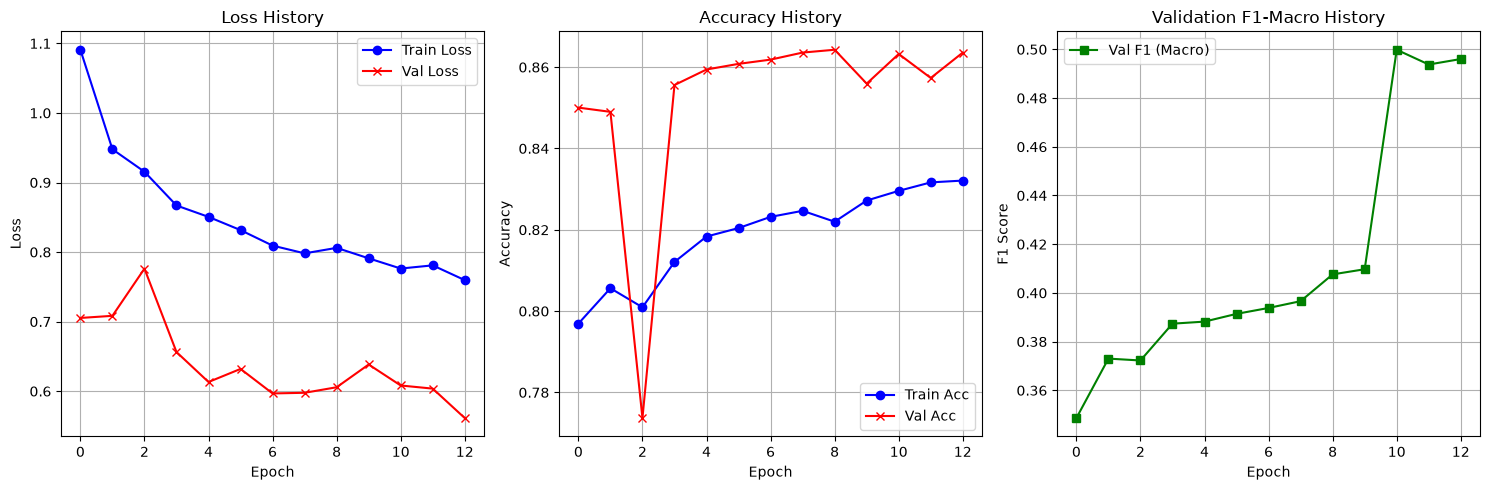

In [19]:
# 5. Plot Training History Curves
plt.figure(figsize=(15, 5))

# Loss curve
plt.subplot(1, 3, 1)
plt.plot(train_history['train_loss'], label='Train Loss', color='blue', marker='o')
plt.plot(train_history['val_loss'], label='Val Loss', color='red', marker='x')
plt.title('Loss History')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy curve
plt.subplot(1, 3, 2)
plt.plot(train_history['train_acc'], label='Train Acc', color='blue', marker='o')
plt.plot(train_history['val_acc'], label='Val Acc', color='red', marker='x')
plt.title('Accuracy History')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score curve
plt.subplot(1, 3, 3)
plt.plot(train_history['val_f1'], label='Val F1 (Macro)', color='green', marker='s')
plt.title('Validation F1-Macro History')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join("results", "training_history.png"))
plt.show()

# Section 5: Evaluation

This section evaluates the model on the test split. It calculates test loss, test accuracy, and test F1-macro. It prints a detailed classification report, saves the confusion matrix plot, and plots sample predictions showing correctly and misclassified images.

In [20]:
# 1. Load best model state dict
best_model_path = os.path.join("results", "solarguard_best.pth")
if os.path.exists(best_model_path):
    model.load_state_dict(torch.load(best_model_path))
    print("Best weights successfully reloaded.")
else:
    print("No best weights file found. Evaluating current state.")

Best weights successfully reloaded.


In [21]:
# 2. Test Set Evaluation Loop
model.eval()
test_running_loss = 0.0
test_correct = 0
test_total = 0
all_preds = []
all_targets = []
all_probs = []
all_images = []

with torch.no_grad():
    for inputs, targets in test_loader:
        # Save inputs for visualization
        all_images.append(inputs.cpu())
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        
        test_running_loss += loss.item() * inputs.size(0)
        probs = torch.softmax(outputs, dim=1)
        prob_vals, predicted = probs.max(1)
        
        test_total += targets.size(0)
        test_correct += predicted.eq(targets).sum().item()
        
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())
        all_probs.extend(prob_vals.cpu().numpy())

test_loss = test_running_loss / test_total
test_acc = test_correct / test_total
test_f1 = f1_score(all_targets, all_preds, average='macro')

all_images = torch.cat(all_images, dim=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test F1-Score (Macro): {test_f1:.4f}")

Test Loss: 0.5935
Test Accuracy: 0.8684
Test F1-Score (Macro): 0.4187


In [22]:
# 3. Print Classification Report
classes_present = sorted(list(set(all_targets)))
target_names = [id_to_class[c] for c in classes_present]

report = classification_report(all_targets, all_preds, target_names=target_names, zero_division=0)
print("Classification Report:")
print(report)

# Save classification report text
with open(os.path.join("results", "classification_report.txt"), "w", encoding="utf-8") as f:
    f.write(report)

Classification Report:
              precision    recall  f1-score   support

        good       0.86      0.96      0.91      1702
       crack       0.56      0.08      0.14       123
      finger       0.47      0.55      0.51       145
  black_core       0.97      0.99      0.98       151
  thick_line       0.56      0.04      0.08       116
  star_crack       0.00      0.00      0.00        19
      corner       0.00      0.00      0.00         1
    fragment       0.00      0.00      0.00         1
     scratch       0.00      0.00      0.00         1
 dislocation       1.00      0.99      0.99       135
    meterial       0.99      1.00      0.99       487

    accuracy                           0.87      2881
   macro avg       0.49      0.42      0.42      2881
weighted avg       0.84      0.87      0.84      2881



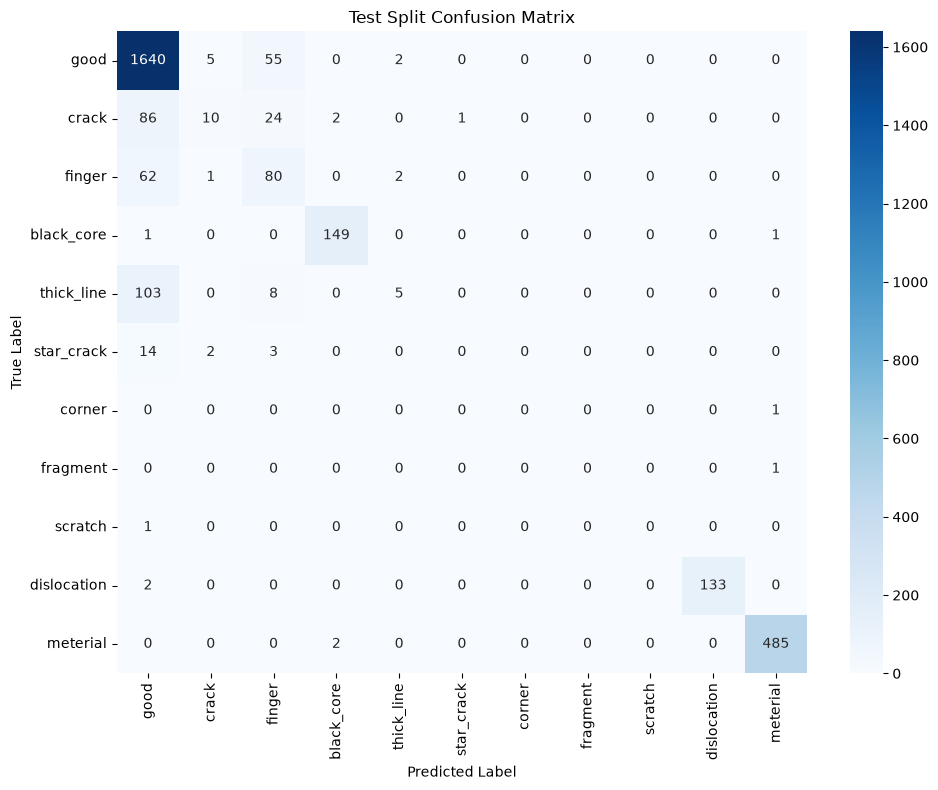

In [23]:
# 4. Confusion Matrix Plot
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(10, 8))
all_class_names = [id_to_class[i] for i in range(11)]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=all_class_names, yticklabels=all_class_names)
plt.title('Test Split Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig(os.path.join("results", "confusion_matrix.png"))
plt.show()

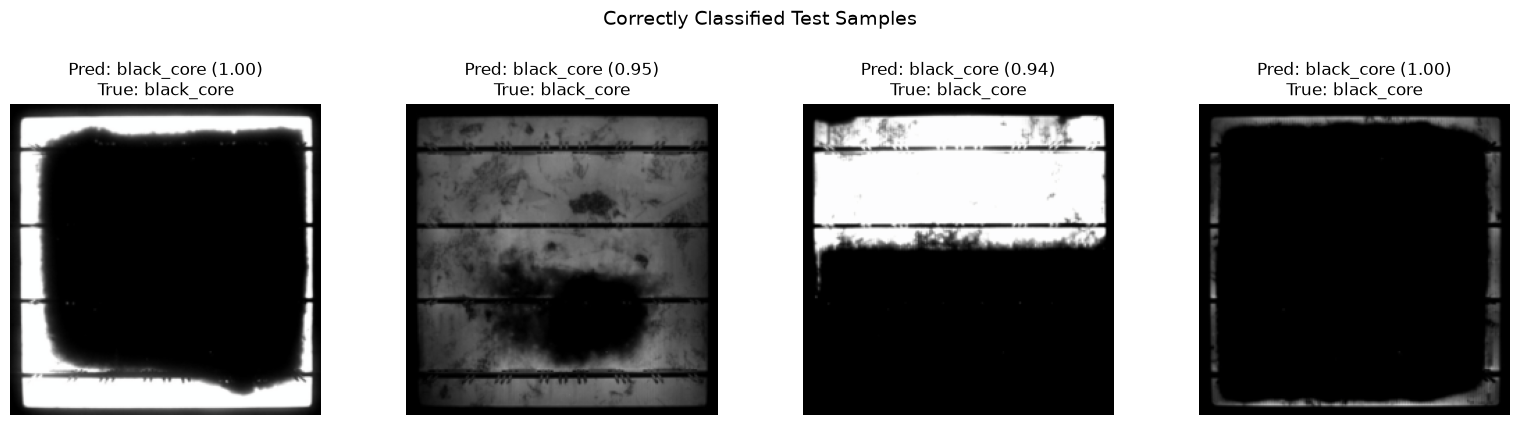

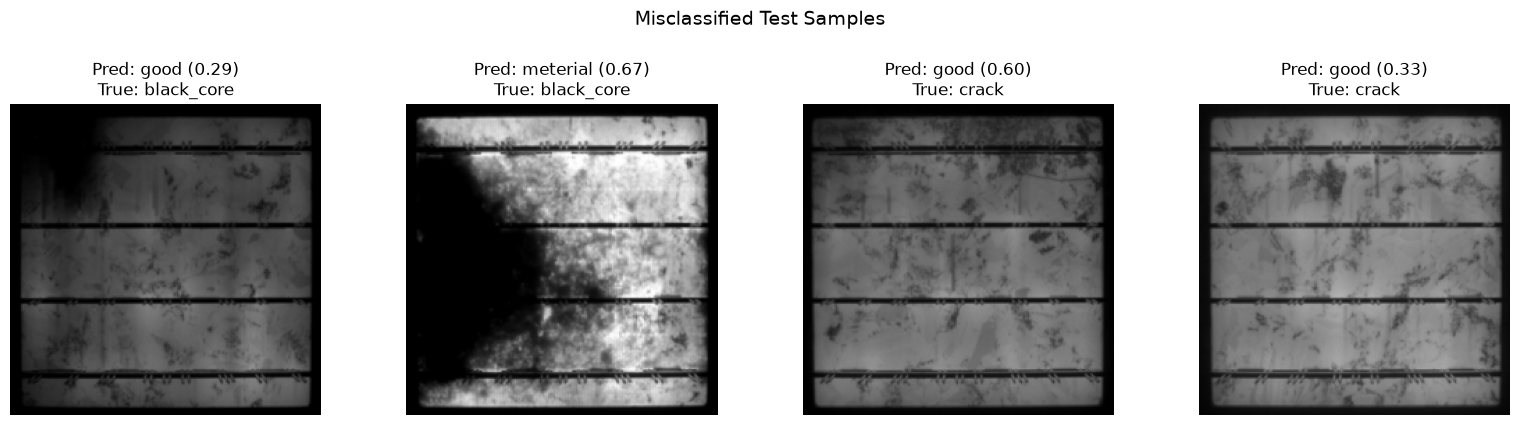

In [24]:
# 5. Correctly and Misclassified Image Visualizations
correct_indices = [i for i, (p, t) in enumerate(zip(all_preds, all_targets)) if p == t]
misclass_indices = [i for i, (p, t) in enumerate(zip(all_preds, all_targets)) if p != t]

def plot_samples(indices, title, max_plots=4):
    plt.figure(figsize=(16, 4))
    plots = min(max_plots, len(indices))
    for i in range(plots):
        idx = indices[i]
        img = all_images[idx].numpy().transpose((1, 2, 0))
        # Unnormalize
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        plt.subplot(1, max_plots, i + 1)
        plt.imshow(img)
        plt.title(f"Pred: {id_to_class[all_preds[idx]]} ({all_probs[idx]:.2f})\nTrue: {id_to_class[all_targets[idx]]}")
        plt.axis('off')
    plt.suptitle(title, fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

if correct_indices:
    plot_samples(correct_indices, "Correctly Classified Test Samples", max_plots=4)
if misclass_indices:
    plot_samples(misclass_indices, "Misclassified Test Samples", max_plots=4)

# Section 6: Model Profiling

This section profiles the DenseNet121 model:
1. Print model structure summary and calculate parameter counts (trainable vs non-trainable) using `torchinfo`.
2. Compute FLOPs on a single image (batch size 1) using `thop`.
3. Measure inference latency on the selected device over 100 consecutive runs using batch size 1.

In [25]:
# 1. Parameter counts using torchinfo
model.eval()
model_summary = summary(model, input_size=(1, 3, 224, 224), verbose=0)
print(model_summary)

# Save summary text to results
with open(os.path.join("results", "model_summary.txt"), "w", encoding="utf-8") as f:
    f.write(str(model_summary))

Layer (type:depth-idx)                   Output Shape              Param #
DenseNet                                 [1, 11]                   --
├─Sequential: 1-1                        [1, 1024, 7, 7]           --
│    └─Conv2d: 2-1                       [1, 64, 112, 112]         (9,408)
│    └─BatchNorm2d: 2-2                  [1, 64, 112, 112]         (128)
│    └─ReLU: 2-3                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-4                    [1, 64, 56, 56]           --
│    └─_DenseBlock: 2-5                  [1, 256, 56, 56]          --
│    │    └─_DenseLayer: 3-1             [1, 32, 56, 56]           (45,440)
│    │    └─_DenseLayer: 3-2             [1, 32, 56, 56]           (49,600)
│    │    └─_DenseLayer: 3-3             [1, 32, 56, 56]           (53,760)
│    │    └─_DenseLayer: 3-4             [1, 32, 56, 56]           (57,920)
│    │    └─_DenseLayer: 3-5             [1, 32, 56, 56]           (62,080)
│    │    └─_DenseLayer: 3-6             [1, 32

In [26]:
# 2. FLOPs calculation using thop
dummy_input = torch.randn(1, 3, 224, 224).to(device)
flops, params = thop.profile(model, inputs=(dummy_input,), verbose=False)
print(f"Total FLOPs (Batch size = 1): {flops / 1e9:.4f} GFLOPs")
print(f"Total Parameters: {params / 1e6:.2f} Million")

# Save profiling stats
with open(os.path.join("results", "profiling_stats.txt"), "w", encoding="utf-8") as f:
    f.write(f"Total FLOPs: {flops / 1e9:.4f} GFLOPs\n")
    f.write(f"Total Parameters: {params / 1e6:.2f} Million\n")

Total FLOPs (Batch size = 1): 2.8960 GFLOPs
Total Parameters: 6.97 Million


In [27]:
# 3. Inference Latency Benchmarking (100 runs, Batch size = 1)
model.eval()
dummy_image = torch.randn(1, 3, 224, 224).to(device)

# Warm-up runs to initialize CUDA context / cache
for _ in range(10):
    with torch.no_grad():
        _ = model(dummy_image)

times = []
for _ in range(100):
    start_time = time.perf_counter()
    with torch.no_grad():
        _ = model(dummy_image)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    end_time = time.perf_counter()
    times.append(end_time - start_time)

avg_latency = np.mean(times) * 1000  # convert to ms
std_latency = np.std(times) * 1000
min_latency = np.min(times) * 1000
max_latency = np.max(times) * 1000
median_latency = np.median(times) * 1000

print(f"Inference Latency over 100 runs (Device: {device.type.upper()}):")
print(f"  Average: {avg_latency:.2f} ms")
print(f"  Median:  {median_latency:.2f} ms")
print(f"  Std Dev: {std_latency:.2f} ms")
print(f"  Min:     {min_latency:.2f} ms")
print(f"  Max:     {max_latency:.2f} ms")

# Append to profiling stats
with open(os.path.join("results", "profiling_stats.txt"), "a", encoding="utf-8") as f:
    f.write(f"Inference Latency average: {avg_latency:.2f} ms\n")
    f.write(f"Inference Latency median: {median_latency:.2f} ms\n")
    f.write(f"Inference Latency std dev: {std_latency:.2f} ms\n")
    f.write(f"Inference Latency min: {min_latency:.2f} ms\n")
    f.write(f"Inference Latency max: {max_latency:.2f} ms\n")

Inference Latency over 100 runs (Device: CUDA):
  Average: 18.27 ms
  Median:  16.10 ms
  Std Dev: 5.74 ms
  Min:     12.31 ms
  Max:     39.21 ms
